# 8장 · 컴퓨터 비전을 위한 딥러닝 (컨브넷)

합성곱 · 풀링을 **손으로 한 번 계산해 보고**, 케라스 층이 똑같이 계산하는지 확인한 다음,
컨브넷을 훈련하고 **안을 열어 봐요**. CPU로 전체 약 5~8분.

| 절 | 내용 | 그림 노트 카드 · 내 필기 |
|---|---|---|
| 1 | 합성곱 손계산 = `Conv2D` · 패딩 · 스트라이드 | 8.1.1 합성곱 연산 |
| 2 | 최대 풀링 손계산 = `MaxPooling2D` · 풀링이 없으면? | 8.1.2 최대 풀링 |
| 3 | MNIST 컨브넷 훈련 · 필터와 특성 맵 들여다보기 | 8.1 |
| 4 | 강아지 vs 고양이 모델 구조 (shape 따라가기) | 8.2 컨브넷 구조 |
| 5 | 데이터 증강: 변환 보기 · 적은 데이터에서 효과 실험 | 8.2.5 데이터 증강 |
| 6 | 사전 훈련 모델: 동결 · 미세 튜닝을 MNIST로 재현 + Xception 구조 | 8.3 사전 훈련된 모델 활용 |

📦 책의 강아지 vs 고양이 데이터는 캐글 다운로드(약 800MB)가 필요해서, 실습은 **MNIST로 같은 원리를 재현**하고 강아지 · 고양이 모델은 구조만 살펴봐요.

🔍 = 내부 들여다보기, 💬 = 설명 포인트.

## 0. 준비

- `KERAS_BACKEND`는 **`import keras` 전에** 정해요. 바꾸려면 커널 재시작 → 이 셀부터 다시.
- 시드를 고정해서 실행할 때마다 거의 같은 결과가 나오게 해요 (CPU 연산 순서 때문에 소수점 끝자리는 조금 달라질 수 있어요).

In [1]:
import os
os.environ["KERAS_BACKEND"] = "jax"   # "tensorflow" / "torch" / "jax"

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)
plt.rcParams["font.family"] = "Malgun Gothic"     # 그래프 한글 깨짐 방지 (윈도)
plt.rcParams["axes.unicode_minus"] = False
print("keras", keras.__version__, "| backend =", keras.backend.backend())

keras 3.15.1 | backend = jax

In [2]:
def plot_history(histories, key="val_loss", title=None, ylim=None):
    """여러 history를 한 그래프에 겹쳐 그리기. histories = {"이름": history}"""
    plt.figure(figsize=(7, 3.6))
    for name, h in histories.items():
        v = h.history[key]
        plt.plot(range(1, len(v) + 1), v, "-o", ms=3, label=name)
    plt.xlabel("에포크"); plt.ylabel(key); plt.title(title or key)
    if ylim: plt.ylim(*ylim)
    plt.legend(); plt.grid(alpha=.3); plt.show()

## 1. 합성곱 연산 손계산 (§8.1.1)

그림 노트 카드의 숫자 그대로: 5×5 입력 * 3×3 필터 → 3×3 특성 맵.
창(3×3)을 한 칸씩 밀면서 **겹치는 칸끼리 곱해서 모두 더해요**.

In [3]:
x = np.array([1, 0, 1, 1, 0,
              0, 1, 1, 0, 1,
              1, 0, 1, 0, 1,
              0, 1, 0, 1, 0,
              1, 1, 0, 1, 1], dtype="float32").reshape(5, 5)
w = np.array([1, 0, 1,
              0, 1, 0,
              1, 0, 1], dtype="float32").reshape(3, 3)

def conv2d_by_hand(x, w):
    H, W = x.shape; k = w.shape[0]
    out = np.zeros((H - k + 1, W - k + 1), dtype="float32")
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            patch = x[i:i + k, j:j + k]          # 창
            out[i, j] = (patch * w).sum()        # 곱해서 합
    return out

fm = conv2d_by_hand(x, w)
print("손계산 특성 맵:\n", fm)
print("왼쪽 위 칸 = 첫 3×3 창 * 필터 =", x[:3, :3].ravel().tolist(), "·", w.ravel().tolist(), "→", fm[0, 0])

손계산 특성 맵:
 [[5. 2. 3.]
 [1. 4. 2.]
 [4. 2. 4.]]
왼쪽 위 칸 = 첫 3×3 창 * 필터 = [1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 1.0, 0.0, 1.0] · [1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0] → 5.0

✏️ **공책 검증 포인트**: 그림 노트 8.1.1 카드의 특성 맵은 처음에 `4 2 4 / 2 4 2 / 3 2 4`로 잘못 그려져 있었어요.
이 노트북의 손계산 · `Conv2D` 결과(`5 2 3 / 1 4 2 / 4 2 4`)로 찾아내서 카드를 고쳤어요. 공책에 옮겨 둔 숫자가 있으면 같이 고치세요.

### 🔍 케라스 `Conv2D`도 똑같이 계산하나?

`Conv2D`의 커널 shape은 `(높이, 너비, 입력 채널, 필터 수)` = `(3, 3, 1, 1)`. 손으로 만든 필터를 그대로 넣어 봐요.
(입력은 `(배치, 높이, 너비, 채널)` = `(1, 5, 5, 1)`)

In [4]:
conv = layers.Conv2D(filters=1, kernel_size=3, use_bias=False)
conv.build((None, 5, 5, 1))
print("커널 shape:", tuple(conv.kernel.shape))
conv.set_weights([w.reshape(3, 3, 1, 1)])
out = keras.ops.convert_to_numpy(conv(x.reshape(1, 5, 5, 1)))[0, :, :, 0]
print(out)
print("손계산과 같은가?", np.allclose(out, fm))

커널 shape: (3, 3, 1, 1)
[[5. 2. 3.]
 [1. 4. 2.]
 [4. 2. 4.]]
손계산과 같은가? True

### 패딩 · 스트라이드 · 필터 수 → 출력 shape

| 설정 | 출력 크기 공식 (입력 n, 창 k, 스트라이드 s) |
|---|---|
| `padding="valid"` (기본) | ⌊(n − k) / s⌋ + 1 |
| `padding="same"` | ⌈n / s⌉ — 가장자리에 0을 둘러 크기 유지 (s=1일 때) |

In [5]:
img = np.random.default_rng(0).random((1, 28, 28, 1)).astype("float32")
for kw in [dict(), dict(padding="same"), dict(strides=2), dict(padding="same", strides=2)]:
    y = layers.Conv2D(32, 3, **kw)(img)
    print(f"Conv2D(32, 3, {', '.join(f'{k}={v!r}' for k, v in kw.items()) or '기본'}) → {tuple(y.shape)}")
print("→ 마지막 축 32 = 필터 개수 = 특성 맵의 '깊이'")

Conv2D(32, 3, 기본) → (1, 26, 26, 32)
Conv2D(32, 3, padding='same') → (1, 28, 28, 32)
Conv2D(32, 3, strides=2) → (1, 13, 13, 32)
Conv2D(32, 3, padding='same', strides=2) → (1, 14, 14, 32)
→ 마지막 축 32 = 필터 개수 = 특성 맵의 '깊이'

💬 **설명 포인트**: Dense와 Conv2D가 배우는 패턴은 어떻게 다를까?

> Dense는 입력 **전체**를 한꺼번에 보는 **전역 패턴**, Conv는 작은 창 안의 **지역 패턴**을 배워요.
> 같은 필터를 이미지 모든 위치에 재사용하니까 ① 한 곳에서 배운 패턴을 어디서든 알아보고(**이동 불변성**) ② 층을 쌓으면 작은 패턴 → 큰 패턴(**공간적 계층 구조**)을 배워요.

## 2. 최대 풀링 손계산 (§8.1.2)

카드의 4×4 특성 맵을 2×2 창, 스트라이드 2로 → 칸마다 **최댓값**만 남겨요.

In [6]:
fmap = np.array([[1, 3, 2, 4],
                 [5, 6, 1, 2],
                 [7, 2, 9, 1],
                 [1, 8, 3, 4]], dtype="float32")
by_hand = fmap.reshape(2, 2, 2, 2).max(axis=(1, 3))     # (블록행, 칸행, 블록열, 칸열)에서 칸 축들을 max
print("손계산:\n", by_hand)

pool = layers.MaxPooling2D(pool_size=2)
k_out = keras.ops.convert_to_numpy(pool(fmap.reshape(1, 4, 4, 1)))[0, :, :, 0]
print("MaxPooling2D:\n", k_out, "\n같은가?", np.allclose(by_hand, k_out))
print("풀링 층의 가중치 개수:", len(pool.weights), "← 배우는 게 없는 고정 연산")

손계산:
 [[6. 4.]
 [8. 9.]]
MaxPooling2D:
 [[6. 4.]
 [8. 9.]] 
같은가? True
풀링 층의 가중치 개수: 0 ← 배우는 게 없는 고정 연산

### 🔍 풀링이 없으면? (§8.1.2의 `model_no_max_pool`)

풀링을 빼고 Conv만 쌓으면 ① 특성 맵이 거의 안 줄어서 Flatten 뒤 Dense 파라미터가 **폭발**하고 ② 마지막 층도 입력의 **작은 영역**만 봐요.

In [7]:
def mnist_convnet(pool=True):
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation="relu")(inputs)
    if pool: x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    if pool: x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation="relu")(x)
    x = layers.Flatten()(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs)

def receptive_field(pool):
    # 각 층을 지날 때 '마지막 층 한 칸이 보는 입력 영역' 크기
    rf, jump = 1, 1
    for kind in (["c", "p", "c", "p", "c"] if pool else ["c", "c", "c"]):
        if kind == "c": rf += 2 * jump
        else: rf += jump; jump *= 2
    return rf

for p in (True, False):
    m = mnist_convnet(p)
    last = [l for l in m.layers if isinstance(l, layers.Conv2D)][-1]
    print(f"풀링 {'있음' if p else '없음'}: 마지막 Conv 출력 {tuple(last.output.shape[1:])}, "
          f"Flatten 길이 {m.layers[-2].output.shape[-1]:6d}, 전체 파라미터 {m.count_params():8,d}, "
          f"마지막 층 한 칸이 보는 입력 {receptive_field(p)}×{receptive_field(p)}")

풀링 있음: 마지막 Conv 출력 (3, 3, 128), Flatten 길이   1152, 전체 파라미터  104,202, 마지막 층 한 칸이 보는 입력 18×18
풀링 없음: 마지막 Conv 출력 (22, 22, 128), Flatten 길이  61952, 전체 파라미터  712,202, 마지막 층 한 칸이 보는 입력 7×7

## 3. MNIST 컨브넷 훈련 (§8.1)

2장의 Dense 모델(정확도 약 97.8%)과 비교해 봐요. 시간을 아끼려고 훈련 샘플 2만 개, 3 에포크만 써요.

In [8]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1)).astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1)).astype("float32") / 255

model = mnist_convnet()
model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()
model.fit(train_images[:20000], train_labels[:20000], epochs=3, batch_size=64, verbose=2)
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
print(f"테스트 정확도: {test_acc:.4f}")

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,202 (407.04 KB)

 Trainable params: 104,202 (407.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
313/313 - 14s - 46ms/step - accuracy: 0.8982 - loss: 0.3218
Epoch 2/3
313/313 - 12s - 39ms/step - accuracy: 0.9746 - loss: 0.0815
Epoch 3/3
313/313 - 13s - 40ms/step - accuracy: 0.9838 - loss: 0.0511
테스트 정확도: 0.9844

### 🔍 내부 들여다보기 ① 첫 번째 Conv 층의 필터 32개

첫 층 커널 shape = `(3, 3, 1, 32)`. 3×3 필터 32개를 그림으로 그려 봐요. 대부분 **방향이 있는 모서리 검출기**처럼 생겼어요.

커널 shape: (3, 3, 1, 32)

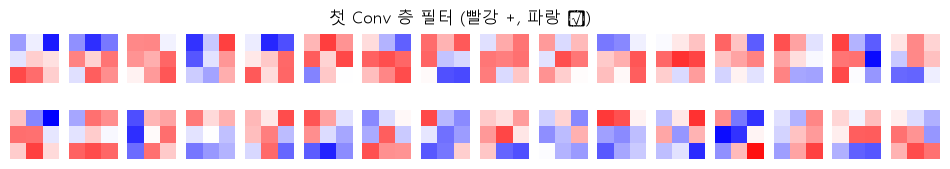

In [9]:
k1 = keras.ops.convert_to_numpy(model.layers[1].kernel)     # layers[0]은 Input
print("커널 shape:", k1.shape)
fig, axes = plt.subplots(2, 16, figsize=(12, 1.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(k1[:, :, 0, i], cmap="bwr", vmin=-abs(k1).max(), vmax=abs(k1).max()); ax.axis("off")
plt.suptitle("첫 Conv 층 필터 (빨강 +, 파랑 −)"); plt.show()

### 🔍 내부 들여다보기 ② 숫자 하나가 층을 지나며 어떻게 바뀌나

함수형 모델이라 중간 층 출력을 한 번에 꺼낼 수 있어요 (7장). 층마다 채널 8개씩만 보여 줘요.

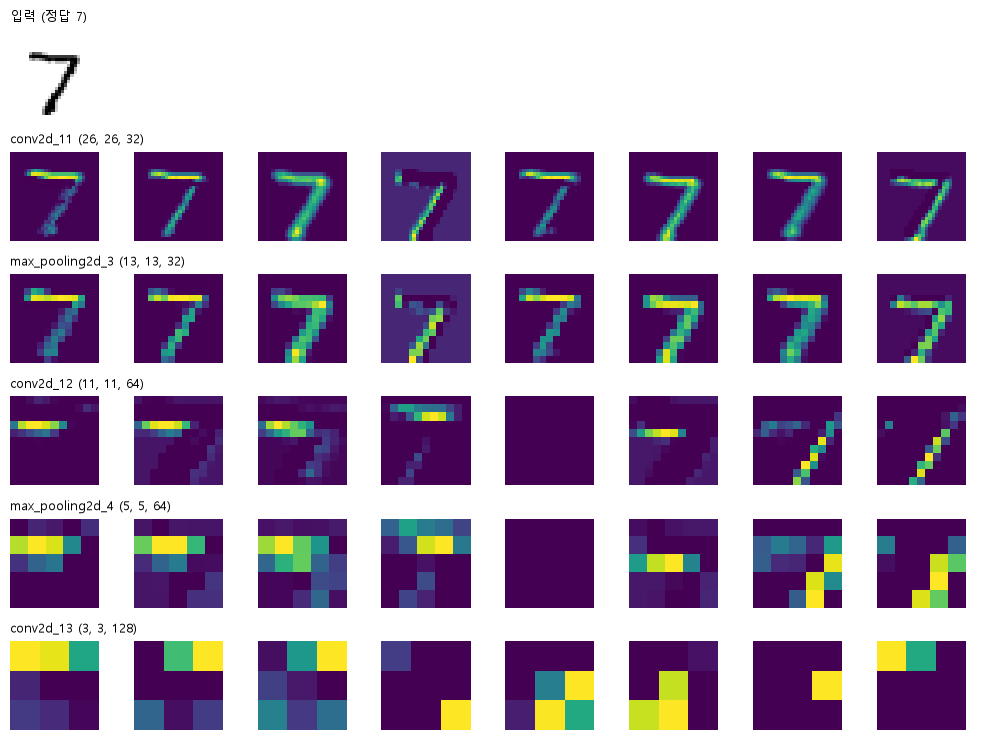

→ 아래로 갈수록 크기는 작아지고(26→1… ) 채널은 많아지며, 사람 눈에는 점점 추상적

In [10]:
conv_pool_layers = [l for l in model.layers if isinstance(l, (layers.Conv2D, layers.MaxPooling2D))]
activation_model = keras.Model(model.inputs, [l.output for l in conv_pool_layers])
acts = activation_model.predict(test_images[:1], verbose=0)

fig, axes = plt.subplots(len(acts) + 1, 8, figsize=(10, 7.5))
axes[0, 0].imshow(test_images[0, :, :, 0], cmap="gray_r")
for ax in axes[0]: ax.axis("off")
axes[0, 0].set_title(f"입력 (정답 {test_labels[0]})", loc="left", fontsize=9)
for r, (layer, a) in enumerate(zip(conv_pool_layers, acts), start=1):
    for c in range(8):
        axes[r, c].imshow(a[0, :, :, c], cmap="viridis"); axes[r, c].axis("off")
    axes[r, 0].set_title(f"{layer.name} {a.shape[1:]}", loc="left", fontsize=9)
plt.tight_layout(); plt.show()
print("→ 아래로 갈수록 크기는 작아지고(26→1… ) 채널은 많아지며, 사람 눈에는 점점 추상적")

## 4. 강아지 vs 고양이 모델 구조 따라가기 (§8.2)

책의 모델을 그대로 만들어 **shape만** 확인해요 (훈련 데이터는 캐글 필요).
그림 노트 8.2 카드의 숫자 `180×180×3 → 89×89×32 → 43×43×64 → 20×20×128 → 9×9×256 → 7×7×256`과 맞춰 보세요.

In [11]:
inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1.0 / 255)(inputs)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(256, 3, activation="relu")(x)
x = layers.Flatten()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
cats_dogs = keras.Model(inputs, outputs)

for l in cats_dogs.layers:
    if isinstance(l, (layers.Conv2D, layers.MaxPooling2D, layers.Flatten)):
        print(f"{l.__class__.__name__:13s} → {tuple(l.output.shape[1:])}")
print("\n파라미터:", f"{cats_dogs.count_params():,}")

Conv2D        → (178, 178, 32)
MaxPooling2D  → (89, 89, 32)
Conv2D        → (87, 87, 64)
MaxPooling2D  → (43, 43, 64)
Conv2D        → (41, 41, 128)
MaxPooling2D  → (20, 20, 128)
Conv2D        → (18, 18, 256)
MaxPooling2D  → (9, 9, 256)
Conv2D        → (7, 7, 256)
Flatten       → (12544,)

파라미터: 991,041

💬 **설명 포인트**: 180 → 178 → 89 처럼 줄어드는 이유는?

> 3×3 Conv(`valid`)가 가장자리 1칸씩 잃어서 −2, 풀링이 절반. 이걸 반복하면 **크기 ↓ 깊이 ↑** — 컨브넷의 공통 패턴이에요.

In [12]:
# 실제로 캐글 데이터를 받아 두었다면 (책 8.2.2): 폴더 → 데이터셋
DATA_DIR = "cats_vs_dogs_small"          # train/ validation/ test/ 아래 cat/ dog/ 폴더
if os.path.isdir(DATA_DIR):
    from keras.utils import image_dataset_from_directory
    train_dataset = image_dataset_from_directory(os.path.join(DATA_DIR, "train"), image_size=(180, 180), batch_size=32)
else:
    print(f"'{DATA_DIR}' 폴더가 없어서 건너뜀 (책 8.2.2 절차로 만들면 이 셀이 데이터셋을 만들어요)")

'cats_vs_dogs_small' 폴더가 없어서 건너뜀 (책 8.2.2 절차로 만들면 이 셀이 데이터셋을 만들어요)

## 5. 데이터 증강 (§8.2.5)

### 5-1. 변환이 어떻게 생겼나

책과 같은 증강 층을 그림 노트 카드의 고양이 그림에 적용해 봐요.

고양이 이미지: (180, 180, 3)
training=False (predict/evaluate) 일 때 원본 그대로? True

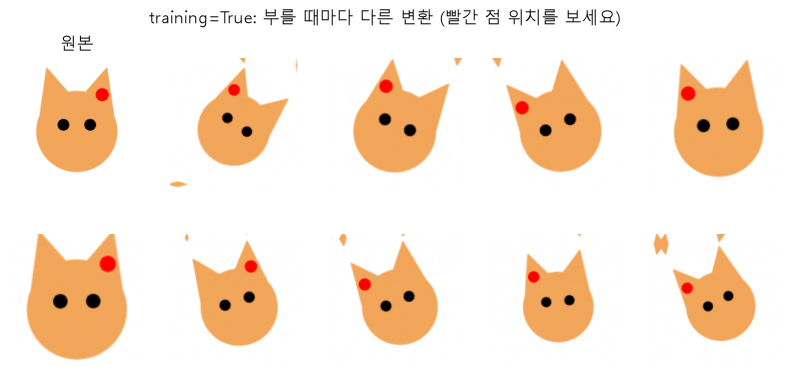

In [13]:
# 카드의 고양이를 이미지로 그리기 (180×180×3)
fig = plt.figure(figsize=(1.8, 1.8), dpi=100); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.axis("off")
ax.add_patch(plt.Circle((0, -0.1), 0.6, color="#f2a65a"))
ax.add_patch(plt.Polygon([[-0.55, 0.15], [-0.45, 0.85], [-0.1, 0.45]], color="#f2a65a"))
ax.add_patch(plt.Polygon([[0.55, 0.15], [0.45, 0.85], [0.1, 0.45]], color="#f2a65a"))
ax.add_patch(plt.Circle((-0.2, 0.0), 0.08, color="k")); ax.add_patch(plt.Circle((0.2, 0.0), 0.08, color="k"))
ax.add_patch(plt.Circle((0.38, 0.45), 0.09, color="red"))                # 오른쪽 귀의 빨간 점 → 뒤집기 확인용
fig.canvas.draw(); cat = np.asarray(fig.canvas.buffer_rgba())[:, :, :3].astype("float32"); plt.close(fig)
print("고양이 이미지:", cat.shape)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
axes[0, 0].imshow(cat.astype("uint8")); axes[0, 0].set_title("원본")
for ax in axes.ravel()[1:]:
    ax.imshow(keras.ops.convert_to_numpy(data_augmentation(cat[None], training=True))[0].astype("uint8"))
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("training=True: 부를 때마다 다른 변환 (빨간 점 위치를 보세요)"); plt.show()

same = np.allclose(keras.ops.convert_to_numpy(data_augmentation(cat[None], training=False))[0], cat)
print("training=False (predict/evaluate) 일 때 원본 그대로?", same)

💬 **설명 포인트**: MNIST 숫자에도 `RandomFlip("horizontal")`을 써도 될까?

> 안 돼요! 좌우가 뒤집힌 '3'은 '3'이 아니고, 뒤집힌 '7'은 다른 글자처럼 보여요. 증강은 **실제로 있을 법한** 변환이어야 해요.
> 숫자에는 작은 회전 · 확대 · 이동만 써요 ↓

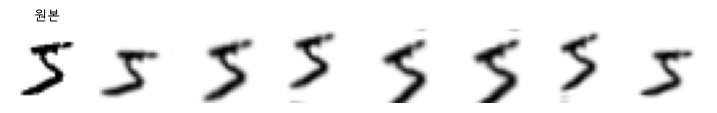

In [14]:
digit_aug = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
])
fig, axes = plt.subplots(1, 8, figsize=(9, 1.4))
for i, ax in enumerate(axes):
    img = train_images[0] if i == 0 else keras.ops.convert_to_numpy(digit_aug(train_images[:1], training=True))[0]
    ax.imshow(img[:, :, 0], cmap="gray_r"); ax.axis("off")
axes[0].set_title("원본", fontsize=9); plt.show()

### 5-2. 실험: 데이터가 적을 때 증강의 효과

책은 강아지 · 고양이 **2,000장**으로 시작해요. 같은 상황을 MNIST **1,000장**으로 만들어서, 증강 + 드롭아웃 있는 모델과 없는 모델을 비교해요.

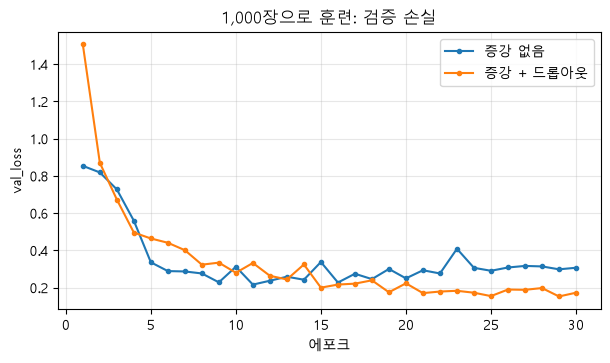

증강 없음     훈련 정확도 1.000 | 최고 검증 정확도 0.944 | 최저 val_loss 0.216 (에포크 11)
증강 + 드롭아웃 훈련 정확도 0.895 | 최고 검증 정확도 0.953 | 최저 val_loss 0.153 (에포크 29)

In [15]:
small_x, small_y = train_images[:1000], train_labels[:1000]
val_x, val_y = train_images[50000:55000], train_labels[50000:55000]

def small_convnet(augment):
    inputs = keras.Input(shape=(28, 28, 1))
    x = digit_aug(inputs) if augment else inputs          # 증강은 모델 맨 앞에
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    if augment: x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    m = keras.Model(inputs, outputs)
    m.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

h_plain = small_convnet(False).fit(small_x, small_y, epochs=30, batch_size=32, validation_data=(val_x, val_y), verbose=0)
h_aug = small_convnet(True).fit(small_x, small_y, epochs=30, batch_size=32, validation_data=(val_x, val_y), verbose=0)
plot_history({"증강 없음": h_plain, "증강 + 드롭아웃": h_aug}, key="val_loss", title="1,000장으로 훈련: 검증 손실")
for name, h in [("증강 없음", h_plain), ("증강 + 드롭아웃", h_aug)]:
    print(f"{name:9s} 훈련 정확도 {h.history['accuracy'][-1]:.3f} | 최고 검증 정확도 {max(h.history['val_accuracy']):.3f} | "
          f"최저 val_loss {min(h.history['val_loss']):.3f} (에포크 {int(np.argmin(h.history['val_loss'])) + 1})")

## 6. 사전 훈련된 모델 활용 (§8.3)

### 6-1. MNIST로 재현: '남이 잘 배운 눈'을 빌려 쓰기

- **사전 훈련**: 숫자 **0~4**만으로 컨브넷을 충분히 훈련 (= ImageNet 역할)
- **새 작업**: 숫자 **5~9** 구분. 레이블 있는 데이터는 **200장**뿐 (= 강아지 · 고양이 역할)

세 방법을 비교해요.
| 방법 | 합성곱 기반 | 새 분류기 |
|---|---|---|
| ⓐ 밑바닥부터 | 랜덤 초기화, 학습 | 학습 |
| ⓑ 특성 추출 | 사전 훈련 가중치, **동결** | 학습 |
| ⓒ 미세 튜닝 | ⓑ 다음, **상위 층만 풀어서** 작은 학습률로 | 학습 |

In [16]:
def conv_base_fn():
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(32, 3, activation="relu", name="conv1")(inputs)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, activation="relu", name="conv2")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, activation="relu", name="conv3")(x)
    x = layers.Flatten()(x)
    return keras.Model(inputs, x, name="conv_base")

# 사전 훈련: 0~4
src = train_labels[:30000] < 5
conv_base = conv_base_fn()
pre = keras.Sequential([conv_base, layers.Dense(5, activation="softmax")])
pre.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
pre.fit(train_images[:30000][src], train_labels[:30000][src], epochs=3, batch_size=64, verbose=0)
print("사전 훈련(0~4) 테스트 정확도:", round(pre.evaluate(test_images[test_labels < 5], test_labels[test_labels < 5], verbose=0)[1], 4))
pretrained_weights = conv_base.get_weights()

# 새 작업: 5~9 (레이블 0~4로 바꿈), 200장
tgt_tr = np.where(train_labels[30000:] >= 5)[0][:200] + 30000
tgt_te = test_labels >= 5
x_new, y_new = train_images[tgt_tr], train_labels[tgt_tr] - 5
x_new_te, y_new_te = test_images[tgt_te], test_labels[tgt_te] - 5
print("새 작업 훈련 샘플:", x_new.shape[0], "| 테스트:", x_new_te.shape[0])

사전 훈련(0~4) 테스트 정확도: 0.9961
새 작업 훈련 샘플: 200 | 테스트: 4861

In [17]:
def new_task_model(pretrained, trainable):
    base = conv_base_fn()
    if pretrained: base.set_weights(pretrained_weights)
    base.trainable = trainable
    m = keras.Sequential([base, layers.Dropout(0.5), layers.Dense(5, activation="softmax")])
    m.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m, base

m_scratch, _ = new_task_model(pretrained=False, trainable=True)
m_scratch.fit(x_new, y_new, epochs=20, batch_size=32, verbose=0)

m_frozen, base_frozen = new_task_model(pretrained=True, trainable=False)
m_frozen.fit(x_new, y_new, epochs=20, batch_size=32, verbose=0)
acc_frozen = m_frozen.evaluate(x_new_te, y_new_te, verbose=0)[1]

# 미세 튜닝: 분류기를 먼저 훈련한 m_frozen에서 이어서, 상위 층(conv3)만 풀고 작은 학습률로
base_frozen.trainable = True
for layer in base_frozen.layers:
    layer.trainable = (layer.name == "conv3")
m_frozen.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])   # trainable 바꾸면 다시 compile!
m_frozen.fit(x_new, y_new, epochs=10, batch_size=32, verbose=0)

print(f"ⓐ 밑바닥부터  테스트 정확도: {m_scratch.evaluate(x_new_te, y_new_te, verbose=0)[1]:.4f}")
print(f"ⓑ 특성 추출   테스트 정확도: {acc_frozen:.4f}")
print(f"ⓒ + 미세 튜닝 테스트 정확도: {m_frozen.evaluate(x_new_te, y_new_te, verbose=0)[1]:.4f}")

ⓐ 밑바닥부터  테스트 정확도: 0.9360
ⓑ 특성 추출   테스트 정확도: 0.9480
ⓒ + 미세 튜닝 테스트 정확도: 0.9486

💬 **설명 포인트**: 결과 읽기

> - ⓑ > ⓐ: 0~4에서 배운 '모서리 · 곡선' 특성이 5~9에도 통해요. 레이블 200장으로는 그 특성을 처음부터 배우기 어려워요.
> - ⓒ ≈ ⓑ: 학습률이 아주 작고(1e-5) 데이터가 200장뿐이라 미세 튜닝으로 얻는 건 작아요. 책의 강아지 · 고양이(2,000장, Xception)에서는 97.5% → 98% 정도로 조금 오르는 정도예요.

### 🔍 내부 들여다보기: `trainable = False`는 정확히 무엇을 바꾸나

동결하면 가중치가 `trainable_weights`에서 빠져서, 옵티마이저가 **업데이트할 목록에 아예 없어요**.

In [18]:
base = conv_base_fn(); base.set_weights(pretrained_weights)
m = keras.Sequential([base, layers.Dense(5, activation="softmax")])
print("동결 전  훈련되는 가중치 텐서 수:", len(m.trainable_weights))
base.trainable = False
print("동결 후  훈련되는 가중치 텐서 수:", len(m.trainable_weights), "(새 Dense의 kernel, bias만)")

m.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy")
before = keras.ops.convert_to_numpy(base.get_layer("conv1").kernel).copy()
m.fit(x_new, y_new, epochs=1, verbose=0)
after = keras.ops.convert_to_numpy(base.get_layer("conv1").kernel)
print("훈련 후 conv1 커널이 그대로인가?", np.allclose(before, after))

동결 전  훈련되는 가중치 텐서 수: 8
동결 후  훈련되는 가중치 텐서 수: 2 (새 Dense의 kernel, bias만)
훈련 후 conv1 커널이 그대로인가? True

💬 **설명 포인트**: 미세 튜닝 전에 왜 **분류기를 먼저** 훈련해야 할까?

> 새 Dense는 랜덤이라 처음엔 오차가 커요. 이때 합성곱 층까지 풀어 두면 그 **큰 그레이디언트**가 사전 학습된 표현을 망가뜨려요.
> 분류기가 먼저 자리를 잡은 뒤, **작은 학습률**로 상위 층만 살짝 조정해요.

### 6-2. 책의 Xception 합성곱 기반 구조

ImageNet 가중치(약 80MB)는 `USE_IMAGENET = True`일 때만 받아요. 구조 · 동결 실습은 가중치 없이도 돼요.

In [19]:
USE_IMAGENET = False
conv_base = keras.applications.Xception(weights="imagenet" if USE_IMAGENET else None,
                                        include_top=False, input_shape=(180, 180, 3))
print("층 개수:", len(conv_base.layers), "| 파라미터:", f"{conv_base.count_params():,}")
print("출력 특성 맵:", tuple(conv_base.output.shape[1:]), "← 강아지 · 고양이 사진 한 장이 이 특성으로 바뀜")

conv_base.trainable = False
print("특성 추출 (전체 동결) 훈련 가중치 텐서:", len(conv_base.trainable_weights))

conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
print("미세 튜닝 (마지막 4개 층만 풀기) 훈련 가중치 텐서:", len(conv_base.trainable_weights),
      "→", [l.name for l in conv_base.layers[-4:]])

층 개수: 132 | 파라미터: 20,861,480
출력 특성 맵: (6, 6, 2048) ← 강아지 · 고양이 사진 한 장이 이 특성으로 바뀜
특성 추출 (전체 동결) 훈련 가중치 텐서: 0
미세 튜닝 (마지막 4개 층만 풀기) 훈련 가중치 텐서: 4 → ['block14_sepconv1_act', 'block14_sepconv2', 'block14_sepconv2_bn', 'block14_sepconv2_act']

---
## 정리 · 스스로 설명해 보기

1. 5×5 입력 * 3×3 필터(valid)의 출력 크기는? `same`이면? 스트라이드 2면? → ______
2. Conv 층의 두 가지 성질 (이동 불변성 · 공간적 계층 구조)을 그림으로 → ______
3. 풀링을 빼면 무슨 일이 생기나? (파라미터 수 · 보는 영역) → ______
4. 증강이 predict 때 꺼지는 이유와, MNIST에 좌우 뒤집기를 안 쓰는 이유는? → ______
5. 특성 추출 vs 미세 튜닝, 그리고 미세 튜닝의 순서는? → ______